Compare saved pooled model fits and their saved behavioral predictions. Establish which
 observations and assumptions they share, compare likelihood and AIC, and inspect behavioral
 agreement. Fitting and simulation are separate procedures that supply this notebook's inputs.

## Parameters and setup


In [1]:
#| code-summary: "1 — Configure the saved fits and response files"


# Observations and work-unit selection
data_path = "data/Dupertuys2026.h5"

# Saved model fits
fit_paths = {
    "CMR": "data/fits/Dupertuys2026_CMR_demo.json",
    "eCMR_source_only": "data/fits/Dupertuys2026_eCMR_source_only.json",
    "eCMR_broad": "data/fits/Dupertuys2026_eCMR_broad.json",
}
simulation_paths = {
    "CMR": "data/simulations/Dupertuys2026_CMR_demo_best_of_3.h5",
    "eCMR_source_only": "data/simulations/Dupertuys2026_eCMR_source_only_demo_best_of_3.h5",
    "eCMR_broad": "data/simulations/Dupertuys2026_eCMR_broad_demo_best_of_3.h5",
}
model_labels = {
    "CMR": "CMR",
    "eCMR_source_only": "Source-only eCMR",
    "eCMR_broad": "Broader eCMR",
}

# Output locations and regeneration
output_dir = "results/model_comparison"


# Behavioral comparisons and figure settings
comparison_analysis_configs = [
    {"target": "jaxcmr.analyses.spc.plot_spc", "title": "Recall by study position"},
    {
        "target": "jaxcmr.analyses.pnr.plot_pnr",
        "title": "First recall",
        "kwargs": {"query_recall_position": 0},
    },
    {
        "target": "jaxcmr.analyses.crp.plot_crp",
        "title": "Temporal transitions",
        "kwargs": {"max_lag": 5},
    },
    {
        "target": "jaxcmr.analyses.cat_recall_rate.plot_cat_recall_rate",
        "title": "Category recall within mixed lists",
        "contrast_name": "Item category",
        "trial_query": "data['list_type'] == 1",
        "kwargs": {
            "category_field": "valence",
            "category_values": [-1, 0],
            "category_labels": ["Emotional", "Neutral"],
            "valid_field": "pres_itemnos",
        },
    },
]
single_analysis_configs = []
analysis_trial_query = "jnp.all(data['pres_itemnos'] > 0, 1)"
confidence_level = 0.95
plot_seed = 0
filter_repeated_recalls = False
figure_dir = None
figure_size = (10, 4.8)
figure_str = "model_and_data"  # Empty displays figures without saving.


# Numerical precision
enable_x64 = True
redo_figures = True


In [2]:
#| code-summary: "2 — Prepare the Colab environment"

import sys

if "google.colab" in sys.modules:
    import subprocess
    from pathlib import Path

    revision = "d919f1ad6aeacc7a36c40b96e365316219a7f40a"
    subprocess.check_call(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            f"jaxcmr[colab] @ git+https://github.com/githubpsyche/jaxcmr.git@{revision}",
        ]
    )
    from jaxcmr.colab import fetch_inputs

    fetch_inputs(
        [
            data_path,
            *fit_paths.values(),
            *simulation_paths.values(),
            *[
                str(Path(path).with_suffix(".json"))
                for path in simulation_paths.values()
            ],
        ],
        revision=revision,
    )


In [3]:
#| code-summary: "3 — Import packages"

import csv
import hashlib
import json
from pathlib import Path

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from tabulate import tabulate

from jaxcmr import repetition
from jaxcmr.fitting import make_scipy_loss_fn
from jaxcmr.helpers import (
    generate_trial_mask,
    import_from_string,
    load_data,
    save_figure,
)


In [4]:
#| code-summary: "4 — Define feature loading and model construction"


def load_features(spec):
    semantic = np.load(spec["embedding_path"]) if spec.get("embedding_path") else None
    categorical = (
        np.load(spec["emotion_feature_path"])[
            :,
            int(spec.get("feature_column", 6)) : int(spec.get("feature_column", 6)) + 1,
        ]
        if spec.get("emotion_feature_path")
        else None
    )
    if spec.get("concat_features", False):
        return np.concatenate([categorical, semantic], axis=1)
    return categorical if categorical is not None else semantic


def construct_model(spec):
    return import_from_string(spec["model_factory"])(
        **{name: import_from_string(path) for name, path in spec["components"].items()}
    )


In [5]:
#| code-summary: "5 — Load observations and establish runtime settings"

jax.config.update("jax_enable_x64", enable_x64)
np.random.seed(plot_seed)
data_path = Path(data_path)
output_dir = Path(output_dir)
output_dir.mkdir(parents=True, exist_ok=True)
data = load_data(str(data_path))
data_sha256 = hashlib.sha256(data_path.read_bytes()).hexdigest()
subjects = np.asarray(data["subject"]).ravel()


## Establish the comparison


In [6]:
#| code-summary: "6 — Load the named pooled fits"

records = {name: json.loads(Path(path).read_text()) for name, path in fit_paths.items()}
display_labels = {name: model_labels.get(name, name) for name in records}


In [7]:
#| code-summary: "7 — Establish matching observations, objectives and stopping rules"

first = next(iter(records.values()))
selected_rows = sorted(first["selected_trial_indices"])
if (
    len(records) < 2
    or not selected_rows
    or len(set(selected_rows)) != len(selected_rows)
):
    raise ValueError(
        "Compare at least two pooled fits with a nonempty observation selection."
    )
for name, record in records.items():
    if record["fits"]["subject"] != [-1] or len(record["fitness"]) != 1:
        raise ValueError(f"{name} is not a single pooled fit.")
    if (
        record["data_sha256"] != data_sha256
        or sorted(record["selected_trial_indices"]) != selected_rows
    ):
        raise ValueError(f"{name}: observations or selected rows differ.")
    if (
        record["loss_function"] != first["loss_function"]
        or record["components"]["termination_policy_create_fn"]
        != first["components"]["termination_policy_create_fn"]
    ):
        raise ValueError("These fits do not use a common objective and stopping rule.")
comparison_mask = (
    jnp.zeros(len(subjects), dtype=bool).at[jnp.asarray(selected_rows)].set(True)
)
print(len(selected_rows), "shared lists; objective:", first["loss_function"])
print("Stopping policy:", first["components"]["termination_policy_create_fn"])


492 shared lists; objective: jaxcmr.loss.transform_sequence_likelihood.ExcludeTerminationLikelihoodLoss
Stopping policy: jaxcmr.components.termination.NoStopTermination


In [8]:
#| code-summary: "8 — Display and save model specifications and parameter roles"

parameter_rows = []
for name, record in records.items():
    print(
        display_labels[name],
        "— factory:",
        record["model_factory"],
        "— components:",
        record["components"],
    )
    parameter_rows += [
        {
            "Model": display_labels[name],
            "Parameter": key,
            "Role": "Estimated" if key in record["free"] else "Fixed",
            "Value": values[0],
            "Bounds": record["free"].get(key),
        }
        for key, values in record["fits"].items()
        if key != "subject"
    ]
print(tabulate(parameter_rows, headers="keys", floatfmt=".5g"))
with (output_dir / "model_parameters.csv").open("w", newline="") as stream:
    writer = csv.DictWriter(stream, fieldnames=list(parameter_rows[0]))
    writer.writeheader()
    writer.writerows(parameter_rows)


CMR — factory: jaxcmr.models.cmr.make_factory — components: {'mfc_create_fn': 'jaxcmr.components.linear_memory.init_mfc', 'mcf_create_fn': 'jaxcmr.components.linear_memory.init_mcf', 'context_create_fn': 'jaxcmr.components.context.init', 'termination_policy_create_fn': 'jaxcmr.components.termination.NoStopTermination'}
Source-only eCMR — factory: jaxcmr.models.ecmr.make_factory — components: {'mfc_create_fn': 'jaxcmr.components.linear_memory.init_mfc', 'mcf_create_fn': 'jaxcmr.components.linear_memory.init_mcf', 'context_create_fn': 'jaxcmr.components.context.init', 'termination_policy_create_fn': 'jaxcmr.components.termination.NoStopTermination'}
Broader eCMR — factory: jaxcmr.models.ecmr.make_factory — components: {'mfc_create_fn': 'jaxcmr.components.linear_memory.init_mfc', 'mcf_create_fn': 'jaxcmr.components.linear_memory.init_mcf', 'context_create_fn': 'jaxcmr.components.context.init', 'termination_policy_create_fn': 'jaxcmr.components.termination.NoStopTermination'}
Model        

## Recalculate the recorded likelihoods


In [9]:
#| code-summary: "9 — Check saved likelihoods against the current inputs"

recalculated = {}
for name, record in records.items():
    model_factory = construct_model(record)
    features = load_features(record)
    loss_class = import_from_string(record["loss_function"])
    fixed = (
        record.get("fit_configuration", {})
        .get("parameters", {})
        .get("fixed", record["fixed"])
    )
    names = tuple(record["free"])
    evaluate = make_scipy_loss_fn(
        loss_class(model_factory, data, features),
        jnp.asarray(selected_rows),
        fixed,
        names,
    )
    values = jnp.asarray([record["fits"][key][0] for key in names])
    recalculated[name] = float(evaluate(values))
    if not np.isclose(recalculated[name], record["fitness"][0], rtol=1e-6, atol=1e-5):
        raise ValueError(
            f"{name}: saved NLL does not match the installed implementation and inputs."
        )
print(
    tabulate(
        [
            {
                "Model": display_labels[name],
                "Saved NLL": record["fitness"][0],
                "Recalculated NLL": recalculated[name],
            }
            for name, record in records.items()
        ],
        headers="keys",
        floatfmt=".6f",
    )
)


Model               Saved NLL    Recalculated NLL
----------------  -----------  ------------------
CMR               7202.029122         7202.029122
Source-only eCMR  7169.426270         7169.426270
Broader eCMR      7164.357873         7164.357873


## Compare scores and searches


In [10]:
#| code-summary: "10 — Calculate and save pooled AIC comparisons"

from jaxcmr.summarize import calculate_aic

# The configured objectives must be unscaled negative log likelihoods.
comparison_records = [
    {**record, "name": name, "fitness": [recalculated[name]]}
    for name, record in records.items()
]
aic_scores = calculate_aic(comparison_records).set_index("Model")["AIC"]
comparison = [
    {
        "Model": display_labels[name],
        "Free parameters": len(record["free"]),
        "Negative log likelihood": recalculated[name],
        "AIC": float(aic_scores.loc[name]),
    }
    for name, record in records.items()
]
best = min(row["AIC"] for row in comparison)
for row in comparison:
    row["Delta AIC"] = row["AIC"] - best
print(tabulate(comparison, headers="keys", floatfmt=".3f"))
with (output_dir / "pooled_model_comparison.csv").open("w", newline="") as stream:
    writer = csv.DictWriter(stream, fieldnames=list(comparison[0]))
    writer.writeheader()
    writer.writerows(comparison)


Model               Free parameters    Negative log likelihood        AIC    Delta AIC
----------------  -----------------  -------------------------  ---------  -----------
CMR                               9                   7202.029  14422.058       73.342
Source-only eCMR                 10                   7169.426  14358.853       10.137
Broader eCMR                     10                   7164.358  14348.716        0.000


In [11]:
#| code-summary: "11 — Display available optimization histories"

search_rows = []
for model_name, fit_record in records.items():
    for run in fit_record.get("search_comparison", {}).get("runs", []):
        search_rows.append(
            {
                "Model": display_labels[model_name],
                "Seed": run["seed"],
                "NLL": run["nll"],
            }
        )
if search_rows:
    print(tabulate(search_rows, headers="keys", floatfmt=".6f"))


Model               Seed          NLL
----------------  ------  -----------
CMR                    0  7202.114181
CMR                    1  7202.029122
Source-only eCMR       0  7169.430814
Source-only eCMR       1  7169.426270
Broader eCMR           0  7164.357873
Broader eCMR           1  7164.407215


## Compare behavioral predictions


In [12]:
#| code-summary: "12 — Load the responses produced by the fitting or simulation procedure"

simulations = {}
for name, record in records.items():
    path = Path(simulation_paths[name])
    metadata = json.loads(path.with_suffix(".json").read_text())
    expected = {
        "data_sha256": data_sha256,
        "selected_trial_indices": selected_rows,
        "fits": record["fits"],
        "model_factory": record["model_factory"],
        "components": record["components"],
        "simulation_function": record["simulation_function"],
    }
    if any(metadata.get(key) != value for key, value in expected.items()):
        raise ValueError(
            f"{name}: saved responses belong to a different fit or observation selection."
        )
    simulated = load_data(str(path))
    if filter_repeated_recalls:
        simulated = dict(simulated)
        simulated["recalls"] = repetition.filter_repeated_recalls(simulated["recalls"])
    simulations[name] = simulated
    print(
        display_labels[name],
        "—",
        path,
        "— seed",
        metadata["seed"],
        "— repetitions",
        metadata["experiment_count"],
    )
figure_dir = Path(figure_dir) if figure_dir is not None else output_dir
figure_dir.mkdir(parents=True, exist_ok=True)


CMR — data/simulations/Dupertuys2026_CMR_demo_best_of_3.h5 — seed 1 — repetitions 10
Source-only eCMR — data/simulations/Dupertuys2026_eCMR_source_only_demo_best_of_3.h5 — seed 1 — repetitions 10
Broader eCMR — data/simulations/Dupertuys2026_eCMR_broad_demo_best_of_3.h5 — seed 1 — repetitions 10


In [13]:
#| code-summary: "13 — Prepare configured model and observation comparisons"

comparison_groups = []
if redo_figures and simulations:
    observed = dict(data)
    if filter_repeated_recalls:
        observed["recalls"] = repetition.filter_repeated_recalls(observed["recalls"])
    datasets = [observed, *simulations.values()]
    names = ["Observed", *[display_labels[name] for name in simulations]]
    comparison_groups.append(
        {
            "analyses": comparison_analysis_configs,
            "datasets": datasets,
            "labels": names,
            "suffix": "",
        }
    )
    for dataset_index, (dataset, label) in enumerate(zip(datasets, names)):
        comparison_groups.append(
            {
                "analyses": single_analysis_configs,
                "datasets": [dataset],
                "labels": [label],
                "suffix": f"_single_{dataset_index}",
            }
        )


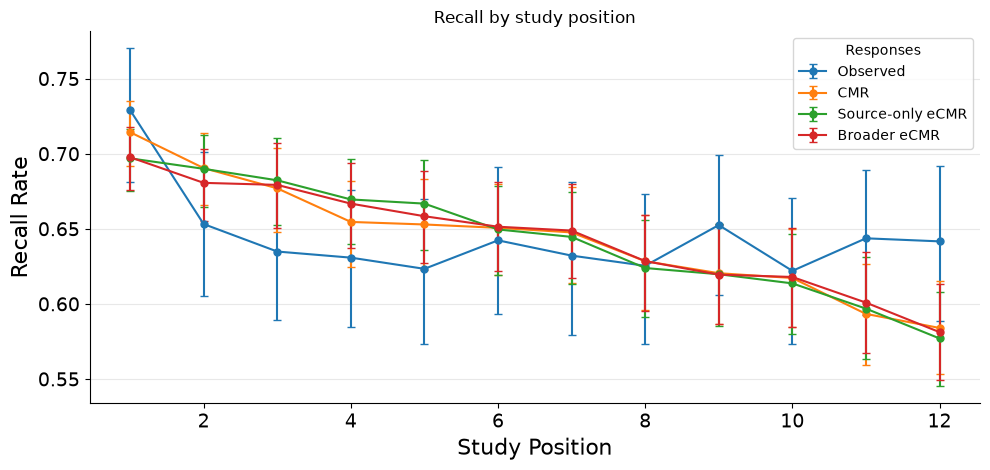

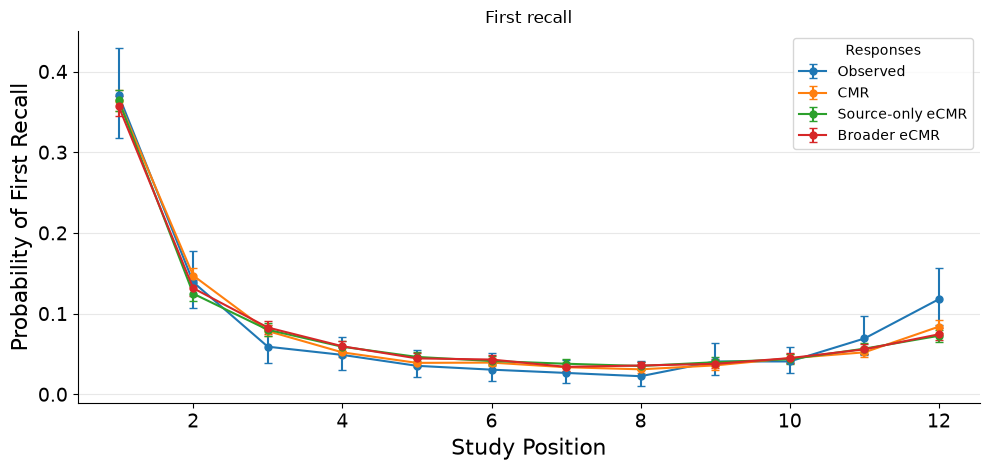

/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


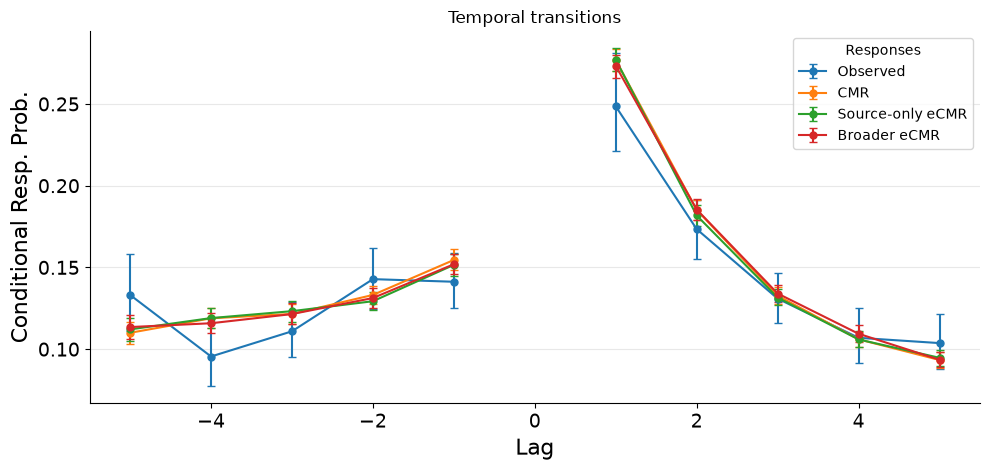

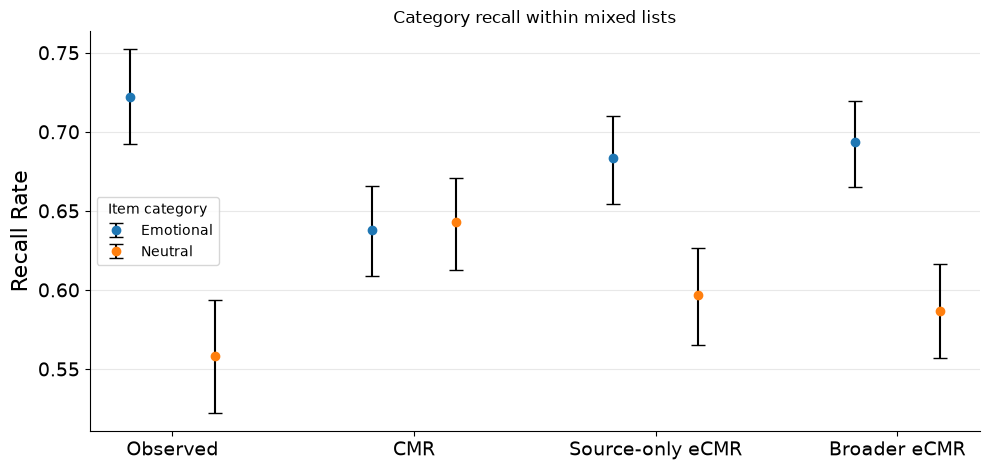

In [14]:
#| code-summary: "14 — Plot and save the configured benchmarks"

for group in comparison_groups:
    analysis_configs = group["analyses"]
    panel_data = group["datasets"]
    curve_labels = group["labels"]
    figure_suffix = group["suffix"]
    for analysis_index, analysis_config in enumerate(analysis_configs):
        plotter = import_from_string(analysis_config["target"])
        masks = [
            generate_trial_mask(
                dataset, analysis_config.get("trial_query", analysis_trial_query)
            )
            for dataset in panel_data
        ]
        masks = [
            trial_mask & comparison_mask if dataset is observed else trial_mask
            for dataset, trial_mask in zip(panel_data, masks)
        ]
        fig, ax = plt.subplots(figsize=analysis_config.get("figsize", figure_size))
        plot_options = {
            "labels": analysis_config.get("labels", curve_labels),
            "contrast_name": analysis_config.get("contrast_name", "Responses"),
            "confidence_level": confidence_level,
            "axis": ax,
            **analysis_config.get("kwargs", {}),
        }
        if analysis_config.get("color_cycle") is not None:
            plot_options["color_cycle"] = analysis_config["color_cycle"]
        plotter(panel_data, masks, **plot_options)
        ax.set_title(analysis_config.get("title", plotter.__name__))
        if analysis_config.get("ylim") is not None:
            ax.set_ylim(analysis_config["ylim"])
        suffix = (
            analysis_config.get("figure_suffix", plotter.__name__.removeprefix("plot_"))
            + figure_suffix
        )
        if (
            sum(
                other["target"] == analysis_config["target"]
                for other in analysis_configs
            )
            > 1
            and "figure_suffix" not in analysis_config
        ):
            suffix += f"_{analysis_index + 1}"
        save_figure(str(figure_dir), figure_str, suffix=suffix)
